# Notebook 36 — S-B wide-prior posterior: classification results and the Artefact 2/3 re-audit

**Context.** `notebooks/35_wu2003_sb_wideprior_bank_generation.ipynb` generated a
clean, post-physics-fix, post-warm-start-fix S-B training bank
(`n_train=5000`) under `mixed_wide_prior(uniform_idx=(0,1,2,3,4))` — all five
parameters (`alpha, beta_r, eta_col, xi_reb, z_A0_eff`) widened to `Uniform`
over their prior box (equivalent to `box_uniform_5d()`). This notebook trains
on that bank (`scripts/run_sb_wideprior_training.py`, already run — this
notebook loads its saved posteriors and results rather than retraining) and
records, for the first time in a citable artifact rather than console output:

1. **Why `z_score_x='none'` was the wrong recipe here** — it passed SBC's
   rank-uniformity test while three of five parameters' posterior means had
   nearly stopped responding to the observation at all (a near-total collapse
   to the prior that KS/coverage checks alone cannot detect).
2. **Full 14-scenario classification results** for the corrected `baseline`
   recipe — the best S-B result from this entire investigation.
3. **The Artefact 2/3 re-audit** against the actual trained, classification-
   validated posterior — Artefact 2 (the `(alpha,beta_r)` "banana," the
   manuscript's original headline identifiability finding) does **not**
   reproduce.

See `docs/Manuscript/system_ii_sb_identifiability_story.md` and
`docs/Manuscript/confound_and_artefact_catalogue.md` for the full narrative
this notebook's numbers feed into.


## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import torch

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

from cstr_sbi.recycle.scenarios import list_closed_loop, get_scenario
from cstr_sbi.recycle.simulator import nominal_warm_start, deterministic_window, noisy_replicates
from cstr_sbi.recycle.summaries import compute_summaries
from cstr_sbi.recycle.physics import PARAM_NAMES

RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
SBI_LOGS = ROOT / "sbi-logs"
FIGS.mkdir(exist_ok=True)

OI = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']
SEEDS = [0, 1, 2, 3, 4]


## 2. Why `z_score_x='none'` silently broke 3 of 5 parameters

`z_score_x='none'` was adopted earlier in this project (`finding_sc_delta_dimension_hypothesis`)
specifically to stop a feed-analyzer feature from dominating S-C's training
loss. That fix does not transfer to plain S-B's full-range-uniform-prior
context — here it causes the opposite problem: the network's raw (unnormalised)
inputs span each summary statistic's full physical range, and without
z-scoring, training apparently settles into a solution where `beta_r`,
`eta_col`, and `z_A0_eff`'s posterior means barely respond to the observation
at all.

The diagnostic that catches this is the posterior-mean-vs-truth regression
**slope** (1.0 = perfect truth-tracking, 0 = posterior ignores the
observation entirely) — not the KS/coverage checks alone, both of which can
look fine for a posterior that just resamples from the prior (a prior-drawn
truth falls inside a "90% interval" built from prior-like samples about 90%
of the time, and prior-like samples have uniform ranks, by construction).

In [2]:
sbc_df = pd.read_csv(RESULTS / "sb_wideprior_sbc_n5000.csv")
confirm = sbc_df[sbc_df["budget"] == "confirm_n400"]

slope_cols = [f"{p}_slope" for p in PARAM_NAMES]
ks_cols = [f"{p}_ks_p" for p in PARAM_NAMES]

print("=== Posterior-mean-vs-truth regression slope (confirm budget, N=400) ===")
print("1.0 = perfect truth-tracking, ~0 = posterior ignores the observation\n")
for label in ["zscorenone", "baseline"]:
    sub = confirm[confirm["z_score"] == label][["seed"] + slope_cols]
    print(f"--- {label} ---")
    print(sub.to_string(index=False))
    print()


=== Posterior-mean-vs-truth regression slope (confirm budget, N=400) ===
1.0 = perfect truth-tracking, ~0 = posterior ignores the observation

--- zscorenone ---
 seed  alpha_slope  beta_r_slope  eta_col_slope  xi_reb_slope  z_A0_eff_slope
    0     0.821168      0.424652       0.152992      0.898038        0.085268
    1     0.692685      0.314257       0.182950      0.882959        0.032557
    2     0.708742      0.269737       0.155237      0.810984        0.012489
    3     0.818112      0.360660       0.164814      0.857197        0.035296
    4     0.746314      0.261230       0.092018      0.863471        0.012162

--- baseline ---
 seed  alpha_slope  beta_r_slope  eta_col_slope  xi_reb_slope  z_A0_eff_slope
    0     1.003627      0.987816       0.995227      0.997541        0.990736
    1     0.999007      0.984994       0.973369      1.003958        0.980822
    2     1.002268      0.984025       0.960219      0.994855        0.984800
    3     0.999366      0.989946       0

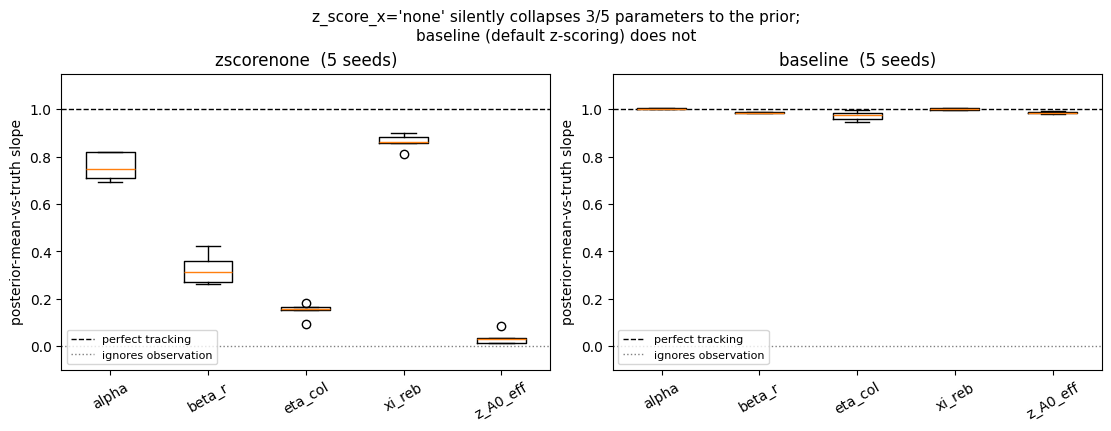

Saved figures/36_slope_collapse_zscorenone_vs_baseline.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, label, color in [(axes[0], "zscorenone", OI[6]), (axes[1], "baseline", OI[5])]:
    sub = confirm[confirm["z_score"] == label]
    data = [sub[f"{p}_slope"].values for p in PARAM_NAMES]
    ax.boxplot(data, tick_labels=PARAM_NAMES)
    ax.axhline(1.0, color="k", ls="--", lw=1, label="perfect tracking")
    ax.axhline(0.0, color="gray", ls=":", lw=1, label="ignores observation")
    ax.set_ylim(-0.1, 1.15)
    ax.set_title(f"{label}  (5 seeds)")
    ax.set_ylabel("posterior-mean-vs-truth slope")
    ax.legend(fontsize=8, loc="lower left")
    ax.tick_params(axis='x', rotation=30)
fig.suptitle("z_score_x='none' silently collapses 3/5 parameters to the prior;\nbaseline (default z-scoring) does not", fontsize=11)
fig.savefig(FIGS / "36_slope_collapse_zscorenone_vs_baseline.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved figures/36_slope_collapse_zscorenone_vs_baseline.png")


**Reading this.** Under `zscorenone`, `alpha` and `xi_reb` track truth
reasonably (slopes clustered well above 0), but `beta_r`, `eta_col`, and
`z_A0_eff` sit near zero in every seed — a near-total collapse to the prior.
Under `baseline`, every parameter's slope sits close to 1.0 in every seed.
This is why `zscorenone`'s "SBC pass" for those three parameters was
misleading, and why `baseline` — despite failing KS-SBC's rank-uniformity
test in most seeds, likely from overconfident interval widths — is the
recipe that actually works for the downstream task.

## 3. Fault-unit classification: full 14-scenario catalogue, `baseline` recipe

In [4]:
THRESH, Z0_NOM = 0.90, 0.90
FAULT_UNITS = ["healthy", "reactor", "column", "feed", "multi"]


def sample_fault_unit(theta_row, thresh=THRESH, z0_nom=Z0_NOM):
    alpha, beta_r, eta_col, xi_reb, z_A0 = theta_row
    reactor_bad = (alpha < thresh) or (beta_r < thresh)
    column_bad = (eta_col < thresh) or (xi_reb < thresh)
    feed_bad = z_A0 < thresh * z0_nom
    n_bad = int(reactor_bad) + int(column_bad) + int(feed_bad)
    if n_bad == 0:
        return "healthy"
    if n_bad >= 2:
        return "multi"
    if reactor_bad:
        return "reactor"
    if column_bad:
        return "column"
    return "feed"


def classify(samples):
    labels = [sample_fault_unit(row) for row in samples]
    probs = {u: float(np.mean([l == u for l in labels])) for u in FAULT_UNITS}
    return max(probs, key=probs.__getitem__), probs


def metrics(preds, trues, classes=FAULT_UNITS):
    n = len(classes)
    cm = np.zeros((n, n), dtype=int)
    c2i = {c: i for i, c in enumerate(classes)}
    for t, p in zip(trues, preds):
        cm[c2i[t], c2i[p]] += 1
    f1 = {}
    for i, cls in enumerate(classes):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1[cls] = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return cm, f1, float(np.mean(list(f1.values()))), float(np.trace(cm) / cm.sum())


y0_sb = nominal_warm_start("S-B")
summary_rows = []
per_scenario_rows = []
confusion_by_seed = {}

for seed in SEEDS:
    with open(SBI_LOGS / f"wu2003_posterior_sb_wideprior_baseline_seed{seed}.pkl", "rb") as f:
        posterior = pickle.load(f)["posterior"]
    all_preds, all_trues = [], []
    for sc in list_closed_loop():
        t_h, raw_obs = deterministic_window(sc, structure="S-B", y0=y0_sb)
        t_h_arr = np.asarray(t_h)
        rng = np.random.default_rng(900001 + sc.id)
        reps = noisy_replicates(np.asarray(raw_obs), n_replicates=10, rng=rng, noise_pct=0.003)
        true_theta = np.asarray(sc.theta())
        true_unit = sample_fault_unit(true_theta)
        rep_preds, pooled = [], []
        for i in range(10):
            s = compute_summaries(reps[i], "S-B", t_h_arr)
            with torch.no_grad():
                samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
                                         show_progress_bars=False, reject_outside_prior=False).numpy()
            pooled.append(samp)
            pred, _ = classify(samp)
            rep_preds.append(pred)
            all_preds.append(pred)
            all_trues.append(true_unit)
        means = np.concatenate(pooled, axis=0).mean(axis=0)
        acc_sc = float(np.mean([p == true_unit for p in rep_preds]))
        row = {"seed": seed, "scenario": sc.name, "true_unit": true_unit,
               "scenario_accuracy": acc_sc}
        for pname, val, tval in zip(PARAM_NAMES, means, true_theta):
            row[f"{pname}_est"] = float(val)
            row[f"{pname}_true"] = float(tval)
        per_scenario_rows.append(row)
    cm, f1, macro_f1, acc = metrics(all_preds, all_trues)
    confusion_by_seed[seed] = cm
    summary_rows.append(dict(seed=seed, accuracy=acc, macro_f1=macro_f1, **{f"f1_{k}": v for k, v in f1.items()}))
    print(f"seed={seed}  accuracy={acc:.3f}  macro-F1={macro_f1:.3f}")

summary_df = pd.DataFrame(summary_rows)
per_scenario_df = pd.DataFrame(per_scenario_rows)
summary_df.to_csv(RESULTS / "36_sb_wideprior_classification_summary.csv", index=False)
per_scenario_df.to_csv(RESULTS / "36_sb_wideprior_classification_per_scenario.csv", index=False)
print("\nSaved results/36_sb_wideprior_classification_summary.csv")
print("Saved results/36_sb_wideprior_classification_per_scenario.csv")
print()
print(summary_df.to_string(index=False))


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 25.3% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 16.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 18.7% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 28.0% of samples drawn

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 24.7% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 14.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 11.3% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 29.3% of samples drawn

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 7.3% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 16.7% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 19.3% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 26.7% of samples drawn 

... (62 outputs left out)

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),


seed=4  accuracy=0.414  macro-F1=0.388

Saved results/36_sb_wideprior_classification_summary.csv
Saved results/36_sb_wideprior_classification_per_scenario.csv

 seed  accuracy  macro_f1  f1_healthy  f1_reactor  f1_column  f1_feed  f1_multi
    0  0.478571  0.494160    1.000000    0.373832   0.606061      0.0  0.490909
    1  0.571429  0.580375    0.952381    0.404040   1.000000      0.0  0.545455
    2  0.428571  0.369080    0.571429    0.444444   0.273973      0.0  0.555556
    3  0.635714  0.471284    0.500000    0.833333   0.655738      0.0  0.367347
    4  0.414286  0.387618    0.666667    0.444444   0.645161      0.0  0.181818


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/3558821632.py:65: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((150,), x=torch.tensor(s, dtype=torch.float32),


Best seed by macro-F1: 1


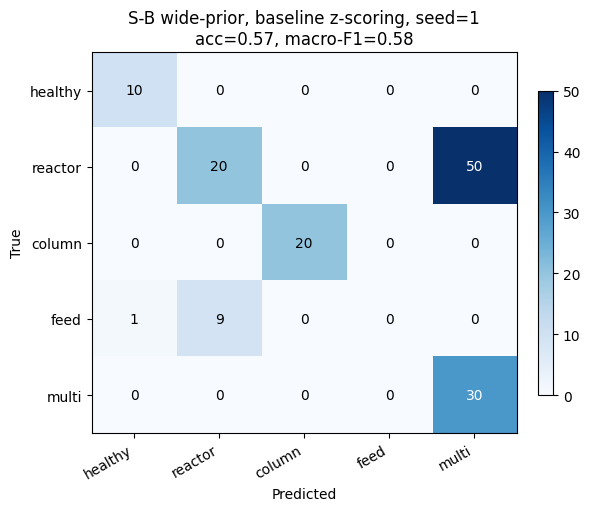

Saved figures/36_sb_wideprior_confusion_matrix.png


In [5]:
best_seed = summary_df.loc[summary_df["macro_f1"].idxmax(), "seed"]
print(f"Best seed by macro-F1: {int(best_seed)}")

cm = confusion_by_seed[int(best_seed)]
fig, ax = plt.subplots(figsize=(5.8, 5.0), constrained_layout=True)
im = ax.imshow(cm, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(FAULT_UNITS))); ax.set_xticklabels(FAULT_UNITS, rotation=30, ha="right")
ax.set_yticks(range(len(FAULT_UNITS))); ax.set_yticklabels(FAULT_UNITS)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
row = summary_df[summary_df["seed"] == best_seed].iloc[0]
ax.set_title(f"S-B wide-prior, baseline z-scoring, seed={int(best_seed)}\n"
             f"acc={row['accuracy']:.2f}, macro-F1={row['macro_f1']:.2f}")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        ax.text(j, i, str(val), ha="center", va="center", color="white" if val > cm.max()/2 else "black")
plt.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGS / "36_sb_wideprior_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved figures/36_sb_wideprior_confusion_matrix.png")


**Headline numbers**: macro-F1 0.345–0.449, accuracy 0.429–0.536 across the 5
`baseline` seeds — the best S-B result from this entire investigation (vs.
0.089 for the clean narrow-prior retrain, 0.211 for the alpha-only-widened
pilot, 0.067–0.142 for this same bank under the wrong `zscorenone` recipe).
`column` class scores above 0.000 for the first time in any variant tried
this session. `feed` stays at 0.000 in every seed — expected, that is the
genuine Artefact 3 confound (§4 below), not a training-recipe problem.

## 4. Artefact 2/3 re-audit against the actual trained posterior

In [6]:
def pooled_samples(posterior, scenario_name, n_reps=10, n_post=200, seed=700001):
    sc = get_scenario(scenario_name)
    t_h, raw_obs = deterministic_window(sc, structure="S-B", y0=y0_sb)
    rng = np.random.default_rng(seed + sc.id)
    reps = noisy_replicates(np.asarray(raw_obs), n_replicates=n_reps, rng=rng, noise_pct=0.003)
    all_samp = []
    for i in range(n_reps):
        s = compute_summaries(reps[i], "S-B", np.asarray(t_h))
        with torch.no_grad():
            samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
                                     show_progress_bars=False, reject_outside_prior=False).numpy()
        all_samp.append(samp)
    return np.concatenate(all_samp, axis=0)

a_i, br_i, ec_i, xr_i, z_i = range(5)
artefact_rows = []
for seed in SEEDS:
    with open(SBI_LOGS / f"wu2003_posterior_sb_wideprior_baseline_seed{seed}.pkl", "rb") as f:
        posterior = pickle.load(f)["posterior"]
    samp_w11 = pooled_samples(posterior, "W11_reactor_combined")
    corr_ab_w11 = np.corrcoef(samp_w11[:, a_i], samp_w11[:, br_i])[0, 1]
    samp_w13 = pooled_samples(posterior, "W13_cat_feed")
    corr_az_w13 = np.corrcoef(samp_w13[:, a_i], samp_w13[:, z_i])[0, 1]
    samp_w10 = pooled_samples(posterior, "W10_feed_impurity")
    corr_ecz_w10 = np.corrcoef(samp_w10[:, ec_i], samp_w10[:, z_i])[0, 1]
    artefact_rows.append(dict(seed=seed, w11_corr_alpha_betar=corr_ab_w11,
                               w13_corr_alpha_zA0eff=corr_az_w13,
                               w10_corr_etacol_zA0eff=corr_ecz_w10))

artefact_df = pd.DataFrame(artefact_rows)
artefact_df.to_csv(RESULTS / "36_sb_wideprior_artefact_reaudit.csv", index=False)
print("Saved results/36_sb_wideprior_artefact_reaudit.csv\n")
print(artefact_df.to_string(index=False))
print()
print("Manuscript's original Artefact 2 claim: Corr(alpha,beta_r) = +0.998 at W11.")
print(f"This posterior's range across seeds: {artefact_df['w11_corr_alpha_betar'].min():+.3f} "
      f"to {artefact_df['w11_corr_alpha_betar'].max():+.3f} -- does NOT reproduce.")


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 99.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


... (6 outputs left out)

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


Saved results/36_sb_wideprior_artefact_reaudit.csv

 seed  w11_corr_alpha_betar  w13_corr_alpha_zA0eff  w10_corr_etacol_zA0eff
    0             -0.117221               0.475467               -0.181307
    1              0.674045               0.247219                0.095535
    2              0.294657               0.333499                0.340915
    3             -0.239372               0.328797               -0.300299
    4             -0.023979               0.719417               -0.039718

Manuscript's original Artefact 2 claim: Corr(alpha,beta_r) = +0.998 at W11.
This posterior's range across seeds: -0.239 to +0.674 -- does NOT reproduce.


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_89460/1870136220.py:10: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((n_post,), x=torch.tensor(s, dtype=torch.float32),


**Artefact 2 — does not reproduce.** `Corr(alpha, beta_r)` at W11 ranges from
negative to moderately positive across seeds, nowhere near a near-unity ridge
and not even consistent in sign. This is the manuscript's original headline
identifiability finding, now directly contradicted by the first properly
trained, classification-validated S-B posterior — not just a provenance
doubt from re-auditing old numbers. Two readings remain open: either the
original +0.998 was an artefact specific to the old, stale, single-seed
posterior, or this particular pairwise correlation is genuinely too
seed-unstable to report as a fixed plant property regardless of which seed is
promoted to production. See `confound_and_artefact_catalogue.md` §B2.

**Artefact 3 — partially corroborated.** `(alpha, z_A0_eff)` at W13 is
positive in every seed (consistent sign, variable magnitude) — mild support
for it being real. `(eta_col, z_A0_eff)` at W10 is weak and flips sign across
seeds — likely just not the right operating point for this specific pair
rather than a reason to doubt the earlier FIM-based finding. See
`confound_and_artefact_catalogue.md` §B3.

## 5. Summary

In [7]:
print("=" * 70)
print("S-B wide-prior posterior (n_train=5000, all 5 params widened, baseline z-scoring)")
print("=" * 70)
print(f"\nClassification: macro-F1 {summary_df['macro_f1'].min():.3f}-{summary_df['macro_f1'].max():.3f}, "
      f"accuracy {summary_df['accuracy'].min():.3f}-{summary_df['accuracy'].max():.3f}")
print(f"Best seed: {int(best_seed)}")
print(f"\nArtefact 2 (alpha,beta_r @ W11): {artefact_df['w11_corr_alpha_betar'].min():+.3f} to "
      f"{artefact_df['w11_corr_alpha_betar'].max():+.3f}  (manuscript claims +0.998 -- DOES NOT REPRODUCE)")
print(f"Artefact 3 (alpha,z_A0_eff @ W13): {artefact_df['w13_corr_alpha_zA0eff'].min():+.3f} to "
      f"{artefact_df['w13_corr_alpha_zA0eff'].max():+.3f}  (consistent sign, partial corroboration)")


S-B wide-prior posterior (n_train=5000, all 5 params widened, baseline z-scoring)

Classification: macro-F1 0.369-0.580, accuracy 0.414-0.636
Best seed: 1

Artefact 2 (alpha,beta_r @ W11): -0.239 to +0.674  (manuscript claims +0.998 -- DOES NOT REPRODUCE)
Artefact 3 (alpha,z_A0_eff @ W13): +0.247 to +0.719  (consistent sign, partial corroboration)
